In [1]:
import pandas as pd
import numpy as np
import sklearn.preprocessing as preproc
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import kurtosis
sns.set(color_codes=True)
pd.set_option("display.max_columns",None)

In [2]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from matplotlib import pyplot
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder



In [3]:
df=pd.read_csv("student_dataV2.csv")
df


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17.0,5.0,171.0,1,1,122.0,1,19,12.0,5.0,9,127.3,1,0,0.0,1,1,0,20,0.0,0,0,0,0,0.000000,0,0,0.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15.0,1.0,9254.0,1,1,160.0,1,1,3.0,3.0,3,142.5,1,0,0.0,0,1,0,19,0.0,0,6,6,6,14.000000,0,0,6.0,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1.0,5.0,9070.0,1,1,122.0,1,37,37.0,9.0,9,124.8,1,0,0.0,0,1,0,19,0.0,0,6,0,0,0.000000,0,0,6.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17.0,2.0,9773.0,1,1,122.0,1,38,37.0,5.0,3,119.6,1,0,0.0,1,0,0,20,0.0,0,6,8,6,13.428571,0,0,6.0,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39.0,1.0,8014.0,0,1,100.0,1,37,38.0,9.0,9,141.5,0,0,0.0,1,0,0,45,0.0,0,6,9,5,12.333333,0,0,6.0,6,6,13.000000,0,13.9,-0.3,0.79,Graduate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4419,1,1.0,6.0,9773.0,1,1,125.0,1,1,1.0,5.0,4,122.2,0,0,0.0,1,1,0,19,0.0,0,6,7,5,13.600000,0,0,6.0,8,5,12.666667,0,15.5,2.8,-4.06,Graduate
4420,1,1.0,2.0,9773.0,1,1,120.0,105,1,1.0,9.0,9,119.0,1,0,1.0,0,0,0,18,1.0,0,6,6,6,12.000000,0,0,6.0,6,2,11.000000,0,11.1,0.6,2.02,Dropout
4421,1,1.0,1.0,9500.0,1,1,154.0,1,37,37.0,9.0,9,149.5,1,0,0.0,1,0,1,30,0.0,0,7,8,7,14.912500,0,0,8.0,9,1,13.500000,0,13.9,-0.3,0.79,Dropout
4422,1,1.0,1.0,9147.0,1,1,180.0,1,37,37.0,7.0,4,153.8,1,0,0.0,1,0,1,20,0.0,0,5,5,5,13.800000,0,0,5.0,6,5,12.000000,0,9.4,-0.8,-3.12,Graduate


In [4]:
df.info() #por que miercale me sale sin nullos y abajo con

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   object 
 1   Application mode                                4423 non-null   float64
 2   Application order                               4423 non-null   float64
 3   Course                                          4421 non-null   float64
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4420 non-null   float64
 7   Nacionality                                     4424 non-null   object 
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

In [5]:
df.isnull().sum()

Marital status                                    0
Application mode                                  1
Application order                                 1
Course                                            3
Daytime/evening attendance                        0
Previous qualification                            0
Previous qualification (grade)                    4
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            1
Mother's occupation                               1
Father's occupation                               1
Admission grade                                   2
Displaced                                         0
Educational special needs                         0
Debtor                                            1
Tuition fees up to date                           1
Gender                                            0
Scholarship holder                                0
Age at enrol

In [6]:
df.describe()

,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Mother's qualification,Father's qualification,Mother's occupation,Admission grade,Educational special needs,Debtor,Gender,Scholarship holder,International,Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4423.000000,4423.000000,4421.000000,4424.000000,4424.000000,4420.000000,4424.000000,4423.000000,4423.000000,4422.000000,4424.000000,4423.000000,4424.000000,4424.000000,4423.000000,4424.000000,4424.000000,4424.000000,4423.000000,4424.000000,4424.000000,4423.000000,4424.000000,4424.000000,4423.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,18.663351,1.727560,8856.331147,0.890823,4.577758,132.621561,19.561935,22.271987,10.961338,126.988512,0.011528,0.113724,0.351718,0.248418,0.024870,6.270570,8.299051,4.706600,10.640100,0.137658,0.541817,6.231743,8.063291,4.435805,10.229941,0.150316,11.566139,1.228029,0.001969
std,17.482509,1.313802,2064.221611,0.311897,10.216592,13.189209,15.603186,15.343244,26.421223,14.476775,0.106760,0.317511,0.477560,0.432144,0.155746,2.480178,4.179106,3.094238,4.843973,0.690880,1.918546,2.196038,3.947951,3.014764,5.211367,0.753774,2.663850,1.382711,2.269935
min,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,0.000000,95.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,2.000000,3.000000,4.000000,117.900000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,6.000000,3.000000,11.000000,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,17.000000,1.000000,9238.000000,1.000000,1.000000,133.100000,19.000000,19.000000,5.000000,126.100000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,8.000000,5.000000,12.285714,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,37.000000,37.000000,9.000000,134.800000,0.000000,0.000000,1.000000,0.000000,0.000000,7.000000,10.000000,6.000000,13.399000,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,57.000000,9.000000,9991.000000,1.000000,43.000000,190.000000,44.000000,44.000000,194.000000,190.000000,1.000000,1.000000,1.000000,1.000000,1.000000,26.000000,45.000000,26.000000,18.875000,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


In [7]:
df.dtypes

Marital status                                     object
Application mode                                  float64
Application order                                 float64
Course                                            float64
Daytime/evening attendance                          int64
Previous qualification                              int64
Previous qualification (grade)                    float64
Nacionality                                        object
Mother's qualification                              int64
Father's qualification                            float64
Mother's occupation                               float64
Father's occupation                                object
Admission grade                                   float64
Displaced                                          object
Educational special needs                           int64
Debtor                                            float64
Tuition fees up to date                            object
Gender        

## no se por que algunos estan con punto despues del numero y otros no, podria ser para que se lean como categorias que son codificadas en numeros, pero no esta en todas las columnas

In [8]:
df['Marital status'].unique() 

array(['1', '2', '4', '?', '3', '5', '6'], dtype=object)

Integer numbers from 1 to 6 ok. just "?" is wrong 

In [9]:
mvf=['?']
df=pd.read_csv("student_dataV2.csv",na_values=mvf)

In [10]:
df['Marital status'].unique()

array([ 1.,  2.,  4., nan,  3.,  5.,  6.])

In [11]:
df['Application mode'].unique()

array([17., 15.,  1., 39., 18., 53., 44., 51., 43.,  7., 42., 16.,  5.,
        2., 10., 57., 26., 27., nan])

Integer numbers corresponding to the specific ones stipuled in the data diccionary.The nan is allredy show as 1 null before

In [12]:
df['Application order'].unique() 

array([ 5.,  1.,  2.,  4.,  3.,  6., nan,  9.,  0.])

Integer numbers from 0 to 9 ok. The nan is allredy show as 1 null before

In [13]:
df['Course'].unique()

array([ 171., 9254., 9070., 9773., 8014., 9991., 9500., 9238., 9670.,
       9853., 9085., 9130., 9556., 9147., 9003.,   33., 9119.,   nan])

Integer numbers corresponding to the specific ones stipuled in the data diccionary: 33 , 171 , 8014, 9003 , 9070, 9085 , 9119 , 9130 ,9147 ,9238,9254 ,9500,9556 ,9670 ,9773 ,9853,9991.  Also the nan is allredy show as 3 null before.

In [14]:
df['Daytime/evening attendance'].unique() #Everithing good here

array([1, 0], dtype=int64)

In [15]:
df['Previous qualification'].unique()

array([ 1, 19, 42, 39, 10,  3, 40,  2,  4, 12, 43, 15,  6,  9, 38,  5, 14],
      dtype=int64)

Integer numbers corresponding to the specific ones stipuled in the data diccionary: 1,2,3,4,5,6,9,10,12,14,15,19,38,39,40,42,43. All good here

In [16]:
df['Previous qualification (grade)'].unique()

array([122. , 160. , 100. , 133.1, 142. , 119. , 137. , 138. , 139. ,
       136. , 133. , 110. , 149. , 127. , 135. , 140. , 125. , 126. ,
       151. , 115. , 150. , 143. , 130. , 120. , 103. , 154. , 132. ,
       167. , 129. , 141. , 116. , 148. , 118. , 106. , 121. , 114. ,
       124. ,   nan, 123. , 113. , 111. , 131. , 158. , 146. , 117. ,
       153. , 178. ,  99. , 134. , 128. , 170. , 155. , 145. , 152. ,
       112. , 107. , 156. , 188. ,  96. , 161. , 166. , 147. , 144. ,
       102. , 101. , 180. , 172. , 105. , 108. , 165. , 190. , 162. ,
       164. , 163. , 159. , 117.4, 175. , 133.8, 176. , 168. , 139.3,
        97. , 157. , 140.8, 184.4, 148.9, 109. , 174. , 182. , 138.6,
        95. , 154.4, 163.3, 145.7, 123.9, 124.4, 169. , 177. , 138.7,
       119.1, 118.9, 126.6])

In [17]:
Previous_qualification_grade_min=df['Previous qualification (grade)'].min()
print(Previous_qualification_grade_min)

95.0


In [18]:
Previous_qualification_grade_max=df['Previous qualification (grade)'].max()
print(Previous_qualification_grade_max)

190.0


The numbers are continuos and bethwen 95 and 190, the range has to be bethwen 0 and 200 so is good. Also the nan is allredy show as 4 null before.

In [19]:
df['Nacionality'].unique()

array([  1.,  62.,   6.,  41.,  26., 103.,  13.,  25.,  21., 101.,  11.,
        22.,  32., 100.,  24., 109.,   2., 108., 105.,  14.,  nan,  17.])

Integer numbers corresponding to the specific ones stipuled in the data diccionary: 1, 2, 6, 11, 13, 14, 17, 21, 22, 24, 25, 26, 32, 41, 62, 100, 101, 103, 105, 108, 109  ok. just "?" is wrong

In [20]:
mvf=['?']
df=pd.read_csv("student_dataV2.csv",na_values=mvf)

In [21]:
df['Nacionality'].unique()

array([  1.,  62.,   6.,  41.,  26., 103.,  13.,  25.,  21., 101.,  11.,
        22.,  32., 100.,  24., 109.,   2., 108., 105.,  14.,  nan,  17.])

In [22]:
df["Mother's qualification"].unique() #Here i change the ' fore " so the programe is not confuse

array([19,  1, 37, 38,  3,  4, 42,  2, 34, 12, 40,  9,  5, 39, 11, 41, 30,
       14, 35, 36,  6, 10, 29, 43, 18, 22, 27, 26, 44], dtype=int64)

In [23]:
df["Father's qualification"].unique() 

array([12.,  3., 37., 38.,  1., 19.,  5.,  4., 34.,  2., 39., 11.,  9.,
       nan, 36., 26., 40., 14., 20., 35., 41., 22., 13., 29., 43., 18.,
       42., 10.,  6., 30., 25., 44., 33., 27., 31.])

In Mother's and Father's qualification is ok, integer numbers corresponding to the specific ones stipuled in the data diccionary:1, 2, 3, 4, 5, 6, 9, 10, 11, 12, 14, 18, 19, 22, 26, 27, 29, 30, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, all good. In  Father's qualification there is one null adecuade detected.

In [24]:
df["Mother's occupation"].unique() 

array([  5.,   3.,   9.,   7.,   4.,   1., 125.,   0.,   6.,   2.,  90.,
         8.,  nan, 141., 175.,  99., 191., 151., 194., 192., 132., 152.,
       134.,  10., 143., 123., 173., 193., 122., 144., 131., 171., 153.])

In Mother's occupation is ok, integer numbers corresponding to the specific ones stipuled in the data diccionary:0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 90, 99, 122, 123, 125, 131, 132, 134, 141, 143, 144, 151, 152, 153, 171, 173, 175, 191, 192, 193, 194, all good. The null is alrredy marked

In [25]:
df["Father's occupation"].unique() 

array(['9', '3', '7', '10', '5', '8', '4', '1', '2', '124', '6', '0',
       '90', '175', '121', '99', '144', '195', '192', '161', '193', '151',
       '182', '132', '131', '194', '163', '135', '143', '171', '103',
       '172', '152', '183', '122', '102', '181', '134', '123', '112',
       '153', '174', '141', '114', nan, 'Five', '101', '154'],
      dtype=object)

In [26]:
mvf=['Five'] #lo dejo como null por ahora
df=pd.read_csv("student_dataV2.csv",na_values=mvf)

In [27]:
df["Father's occupation"].unique()  

array([  9.,   3.,   7.,  10.,   5.,   8.,   4.,   1.,   2., 124.,   6.,
         0.,  90., 175., 121.,  99., 144., 195., 192., 161., 193., 151.,
       182., 132., 131., 194., 163., 135., 143., 171., 103., 172., 152.,
       183., 122., 102., 181., 134., 123., 112., 153., 174., 141., 114.,
        nan, 101., 154.])

In [28]:
df["Admission grade"].unique() 

array([127.3, 142.5, 124.8, 119.6, 141.5, 114.8, 128.4, 113.1, 129.3,
       123. , 130.6, 119.3, 130.2, 111.8, 137.1, 120.7, 137.4, 136.3,
       124.6, 120.3, 121.8, 125.5, 114.9, 123.9, 157. , 116.4, 131. ,
       122.1, 118.8, 150. , 130. , 138.8, 134.5, 131.4, 102.5, 128.8,
       122.9, 113.9, 120. , 121.1, 120.4, 100.6, 121.4, 109.7, 134.1,
       127.6, 132.4, 133.4, 126.1, 113.5, 121.3, 159.3, 129.1, 155.3,
       139.8, 115.2, 131.9, 126. , 120.9, 128.2, 120.1, 100. , 134. ,
       130.8, 135.8, 111.7, 132.9, 115.5, 106. , 117. , 110.2, 155.7,
       180.4, 110. , 161. , 117.6, 128.7, 112.2, 100.8, 105. , 114. ,
       137. , 124.9, 134.3, 111.5, 160. , 117.4, 122.2, 118.2, 106.7,
       108.2, 107. , 136.1, 115.3, 140.4, 113.4, 118.6, 122.3, 127.9,
       117.1, 145.3, 122.6, 128. , 123.7, 131.7, 133.2, 109.3, 113. ,
       157.9, 112.1, 174.7, 110.1,  99.7, 121. , 119.1, 124.7, 117.2,
       131.5, 121.7, 123.4, 132.8, 108.7, 138.1, 126.5, 127.4, 123.6,
       122. , 125.8,

In [29]:
Admission_grade_min=df['Admission grade'].min()
print(Admission_grade_min)

95.0


In [30]:
Admission_grade_max=df['Admission grade'].max()
print(Admission_grade_max)

190.0


In [31]:
df["Displaced"].unique()  # the first time i runed the cel it was a ?, vut after it get fixed wen I marked that as nan in other feature

array(['1', '0', '?'], dtype=object)

In [32]:
df["Educational special needs"].unique() #ok

array([0, 1], dtype=int64)

In [33]:
df["Debtor"].unique() #ok, marca su nan correctamente

array([ 0.,  1., nan])

In [34]:
df["Tuition fees up to date"].unique() #ok, nan corregido por codigo anterior

array(['1', '0', nan, '?'], dtype=object)

In [35]:
df["Gender"].unique() #ok

array([1, 0], dtype=int64)

In [36]:
df["Scholarship holder"].unique() #ok

array([0, 1], dtype=int64)

In [37]:
df["Age at enrollment"].unique() 

array(['20', '19', '45', '50', '18', '22', '21', '34', '37', '43', '55',
       '39', '29', '24', '27', '23', '26', '33', '35', '25', '44', '36',
       '47', '28', '38', 'UnKnown', '30', '31', '32', '40', '42', '48',
       '49', '46', '41', '70', '60', '53', '51', '52', '54', '61', '58',
       '59', '17', '57', '62', nan], dtype=object)

In [38]:
mvf=['UnKnown'] 
df=pd.read_csv("student_dataV2.csv",na_values=mvf)

In [39]:
df["International"].unique() #ok with correct nan

array([ 0.,  1., nan])

In [40]:
df["Curricular units 1st sem (credited)"].unique() 

array(['0', '2', '3', '6', '7', '13', '4', '1', '5', '19', '11', '8',
       '10', '9', '15', '12', '14', '18', '17', '16', '20', 'Na'],
      dtype=object)

In [41]:
mvf=['Na'] 
df=pd.read_csv("student_dataV2.csv",na_values=mvf)

In [42]:
df["Curricular units 1st sem (enrolled)"].unique() #ok

array([ 0,  6,  5,  7,  8,  1, 12, 10, 18,  9, 21,  3, 17, 16, 11, 14, 13,
        2,  4, 15, 19, 23, 26], dtype=int64)

In [43]:
df["Curricular units 1st sem (evaluations)"].unique() #ok

array([ 0,  6,  8,  9, 10,  5,  7, 14, 12, 15, 13, 11,  1, 17, 18, 19, 21,
        4, 16,  3, 24,  2, 22, 45, 20, 26, 29, 36, 32, 23, 27, 31, 28, 25,
       33], dtype=int64)

In [44]:
df["Curricular units 1st sem (approved)"].unique() #ok

array([ 0,  6,  5,  7,  4,  1,  3,  2,  8, 18, 10,  9, 21, 11, 13, 12, 16,
       14, 17, 19, 15, 20, 26], dtype=int64)

In [45]:
df["Curricular units 1st sem (grade)"].unique() 

array([ 0.        , 14.        , 13.42857143, 12.33333333, 11.85714286,
       13.3       , 13.875     , 11.4       , 13.21428571, 10.57142857,
       13.25      , 13.2       , 12.        , 13.30625   , 12.5       ,
       11.66666667, 11.4375    , 12.85714286, 13.375     , 13.29666667,
       11.6       , 11.375     , 12.66666667, 12.93333333, 12.83333333,
       11.33333333, 12.4       , 10.        , 11.        , 12.75      ,
       14.8       , 13.928     , 13.        , 11.5       , 13.51666667,
       13.66666667, 11.83333333, 14.71428571, 10.6       , 13.04444444,
       14.935     , 13.13333333, 11.9       , 12.57142857, 11.2       ,
       11.975     , 10.33333333, 10.5       , 14.84285714, 12.2       ,
       12.16666667, 13.08      , 10.66666667, 11.875     , 13.75      ,
       14.2       , 11.96      , 12.875     , 14.63157895, 13.26666667,
       13.85714286, 13.4       , 12.51666667, 11.61666667, 13.14285714,
       12.6       , 10.8       , 12.8       , 14.16666667, 12.1 

In [46]:
Curricular_units_1st_sem_min=df['Curricular units 1st sem (grade)'].min()
print(Curricular_units_1st_sem_min)

0.0


In [47]:
Curricular_units_1st_sem_max=df['Curricular units 1st sem (grade)'].max() 
print(Curricular_units_1st_sem_max)

18.875


The grades are bethen 0 and 20 as the data diccionary indicate and the null is marked

In [48]:
df["Curricular units 1st sem (without evaluations)"].unique() #ok

array([ 0,  1,  2,  4,  3,  6, 12, 10,  7,  5,  8], dtype=int64)

In [49]:
df["Curricular units 2nd sem (credited)"].unique() #ok

array([ 0,  1,  2,  5,  7,  4, 10,  3, 13,  9,  6, 11, 12,  8, 14, 15, 16,
       18, 19], dtype=int64)

In [50]:
df["Curricular units 2nd sem (enrolled)"].unique() #ok correct nan

array([ 0.,  6.,  5.,  8.,  7., 11., 12.,  9., 13., 19.,  3., 10.,  4.,
       nan, 17.,  2.,  1., 14., 15., 16., 23., 18., 21.])

In [51]:
df["Curricular units 2nd sem (evaluations)"].unique() #ok

array([ 0,  6, 10, 17,  8,  5,  7, 14,  9, 12, 11, 13, 19,  3, 15, 16,  4,
       18,  2, 21,  1, 26, 27, 22, 20, 24, 28, 23, 25, 33], dtype=int64)

In [52]:
df["Curricular units 2nd sem (approved)"].unique() #ok

array([ 0,  6,  5,  8,  2,  7,  4,  1,  3, 10, 13, 11, 19,  9, 12, 17, 14,
       20, 16, 18], dtype=int64)

In [53]:
df["Curricular units 2nd sem (grade)"].unique() 

array([ 0.        , 13.66666667, 12.4       , 13.        , 11.5       ,
       14.345     , 14.14285714, 13.5       , 14.2       , 13.21428571,
       11.        , 12.        , 14.545     , 12.25      , 11.425     ,
       12.85714286, 12.28571429, 14.11428571, 13.28571429, 12.33333333,
       13.71666667, 10.57142857, 13.4       , 14.375     , 13.42857143,
       10.        , 11.6       , 15.8       , 14.34285714, 13.8       ,
       14.33333333, 13.2       , 13.77142857, 12.83333333, 14.16666667,
       11.83333333, 13.595     , 12.9       , 14.935     , 12.22142857,
       12.42857143, 10.75      , 10.8       , 13.75      , 10.85714286,
       13.33333333, 15.05555556, 11.66666667, 12.2       , 13.3       ,
       11.33333333, 13.08      , 11.2       , 13.25      , 14.47777778,
       14.23076923, 12.27272727, 12.3       , 15.        , 12.8       ,
       12.57142857, 12.51666667, 10.66666667, 11.4       , 14.        ,
       11.25      , 13.77777778, 15.01111111, 13.74285714, 14.6 

In [54]:
Curricular_units_2nd_sem_min=df['Curricular units 2nd sem (grade)'].min()
print(Curricular_units_2nd_sem_min)

0.0


In [55]:
Curricular_units_2nd_sem_max=df['Curricular units 2nd sem (grade)'].max()
print(Curricular_units_2nd_sem_max)

18.571428571428573


Ok bethwen 0 an 20, null marked. Same as Curricular units 1st sem (grade) is continuos marked in data diccionary as integral number

In [56]:
df["Curricular units 2nd sem (without evaluations)"].unique() #ok

array([ 0,  5,  2,  1,  3,  6,  4, 12,  7,  8], dtype=int64)

In [57]:
df=df.astype({})

In [58]:
df["Unemployment rate"].unique() #ok continuo

array([10.8, 13.9,  9.4, 16.2, 15.5,  8.9, 12.7, 11.1,  7.6, 12.4])

In [59]:
df["Inflation rate"].unique() #ok continuo, - is deflacion

array([ 1.4, -0.3, -0.8,  0.3,  2.8,  3.7,  0.6,  2.6,  0.5])

In [60]:
df["GDP"].unique() #ok continuo,is GDP rate in reality aparently

array([ 1.74,  0.79, -3.12, -0.92, -4.06,  3.51, -1.7 ,  2.02,  0.32,
        1.79])

In [61]:
df["Target"].unique() 

array(['Dropout', 'Graduate', 'Enrolled', 'Grad', 'graduate', 'Drop',
       'dropout'], dtype=object)

In [62]:
df["Target"]=df["Target"].replace("Grad","Graduate")

In [63]:
df["Target"]=df["Target"].replace("graduate","Graduate")

In [64]:
df["Target"]=df["Target"].replace("Drop","Dropout")

In [65]:
df["Target"]=df["Target"].replace("dropout","Dropout")

In [66]:
df["Father's occupation"]=df["Father's occupation"].replace("Five","5")

In [67]:
df["Father's occupation"].unique()  

array(['9', '3', '7', '10', '5', '8', '4', '1', '2', '124', '6', '0',
       '90', '175', '121', '99', '144', '195', '192', '161', '193', '151',
       '182', '132', '131', '194', '163', '135', '143', '171', '103',
       '172', '152', '183', '122', '102', '181', '134', '123', '112',
       '153', '174', '141', '114', nan, '101', '154'], dtype=object)

In [68]:
Category_columns={"Application order":"category","Father's occupation":"category", "Marital status":"category", "Application mode":"category",	"Course":"category",	"Daytime/evening attendance":"category",	"Previous qualification":"category",	"Nacionality":"category"	, "Mother's qualification":"category"	,"Father's qualification":"category"	,"Mother's occupation":"category"	,"Father's occupation":"category"	,"Displaced":"category","Educational special needs":"category"	,"Debtor":"category", "Tuition fees up to date":"category","Gender":"category"	, "Scholarship holder":"category",	"International":"category",	"Target":"category"} 
df=df.astype(Category_columns) #no logre marcar las int y flot, pero vienen numericas por defecto asi que filo

 # ojo escalo solo para analisis, en el entrenamiento solo se escalan los datos de entrenamienot

In [69]:
features_to_standardize= ["Application order","Previous qualification (grade)", "Admission grade", "Age at enrollment", "Curricular units 1st sem (credited)" , "Curricular units 1st sem (enrolled)","Curricular units 1st sem (evaluations)","Curricular units 1st sem (approved)","Curricular units 1st sem (grade)","Curricular units 1st sem (without evaluations)", "Curricular units 2nd sem (credited)","Curricular units 2nd sem (enrolled)","Curricular units 2nd sem (evaluations)","Curricular units 2nd sem (approved)","Curricular units 2nd sem (grade)", "Curricular units 2nd sem (without evaluations)","Unemployment rate","Inflation rate","GDP"]

In [70]:
mvf=['Na',"UnKnown"]
df=pd.read_csv("student_dataV2.csv",na_values=mvf) #por alguna razon los que ya pase a nan esta formula culia los sigue leyendo mal

In [71]:
Family_Context={"Father's occupation", "Mother's qualification","Father's qualification","Mother's occupation","Father's occupation"} 

In [72]:
Enroll_Numerical_Features=["Application order","Previous qualification (grade)", "Admission grade", "Age at enrollment"]

In [73]:
First_Semester_Numerical_Features=["Curricular units 1st sem (credited)" , "Curricular units 1st sem (enrolled)","Curricular units 1st sem (evaluations)","Curricular units 1st sem (approved)","Curricular units 1st sem (without evaluations)","Curricular units 1st sem (grade)"]

In [74]:
Second_Semester_Numerical_Features=["Curricular units 2nd sem (credited)","Curricular units 2nd sem (enrolled)","Curricular units 2nd sem (evaluations)","Curricular units 2nd sem (approved)", "Curricular units 2nd sem (without evaluations)","Curricular units 2nd sem (grade)"]

In [75]:
Context_Numerical_Features=["Unemployment rate","Inflation rate","GDP"]

In [76]:
print(df.columns.tolist())

['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP', 'Target']


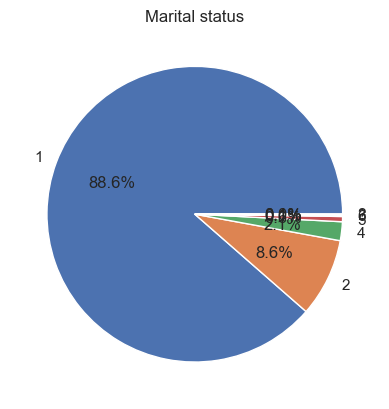

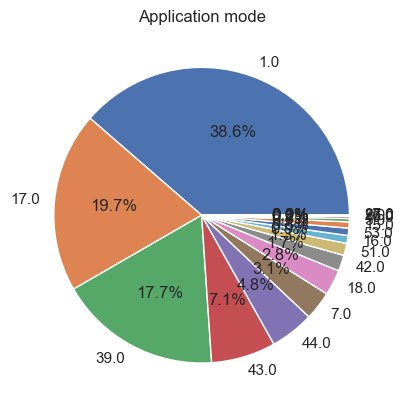

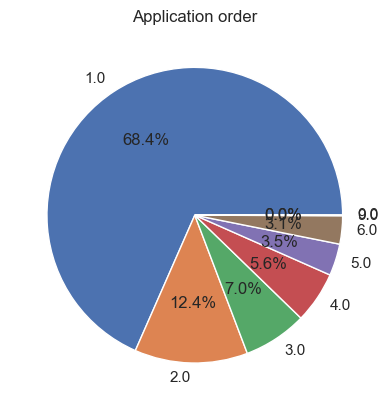

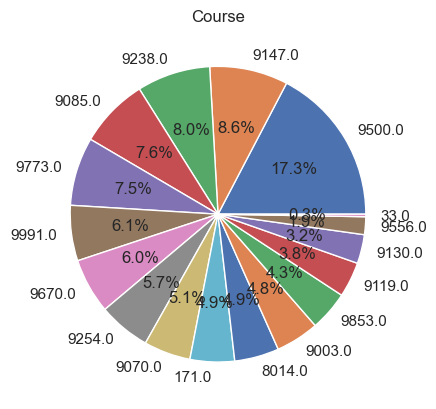

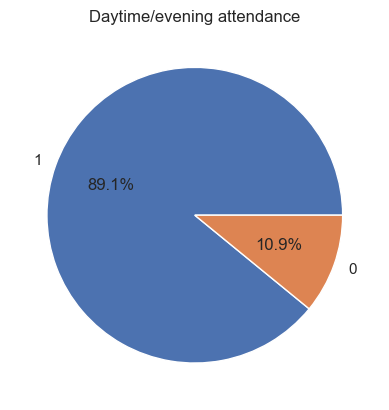

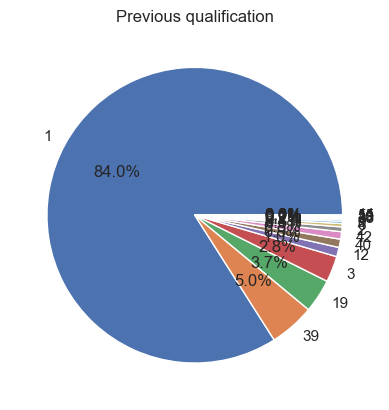

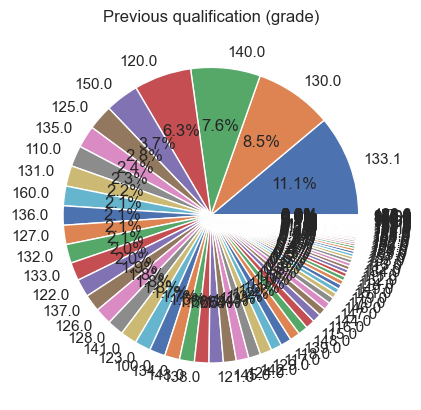

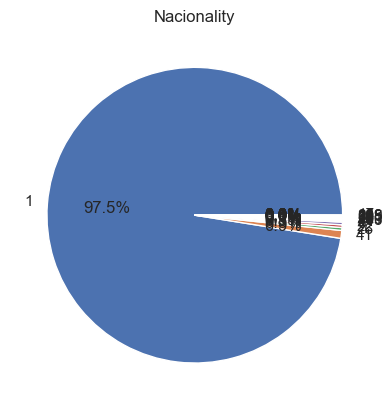

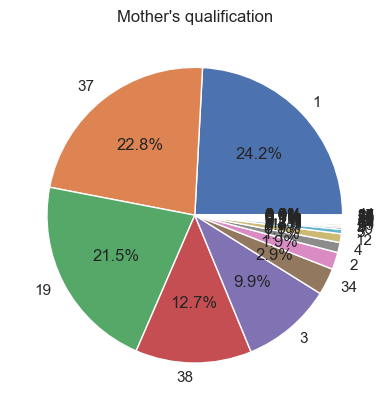

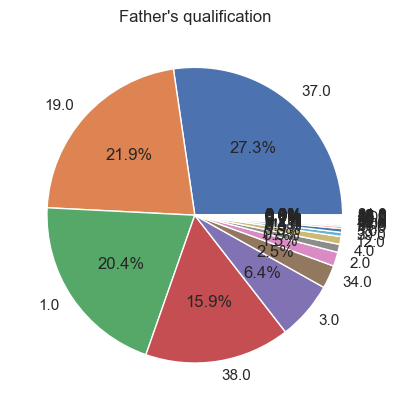

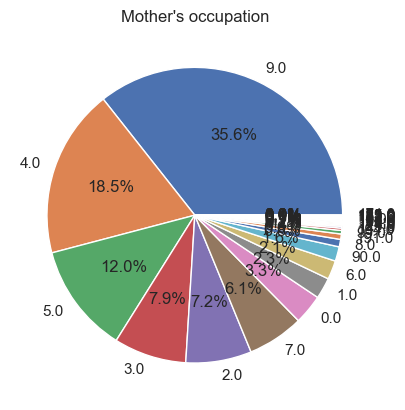

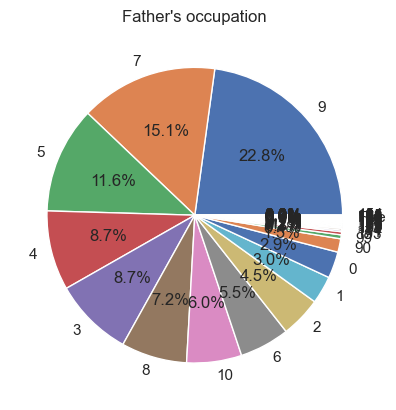

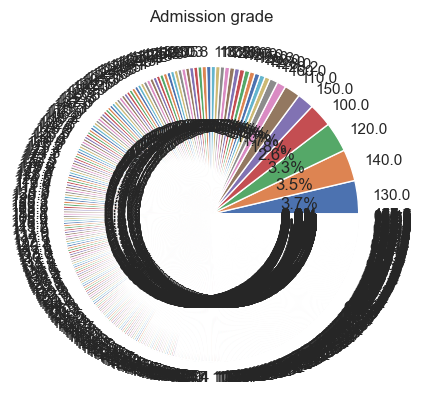

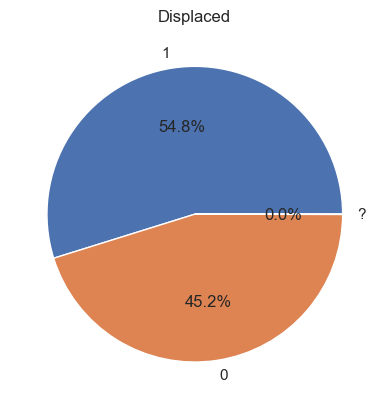

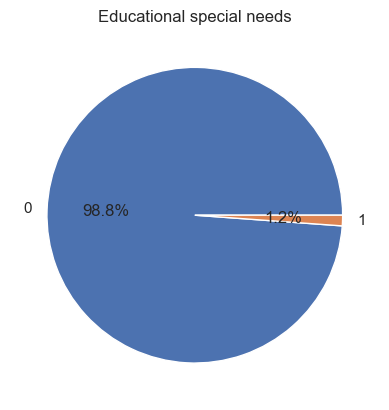

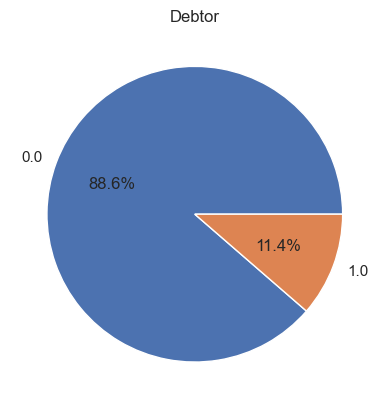

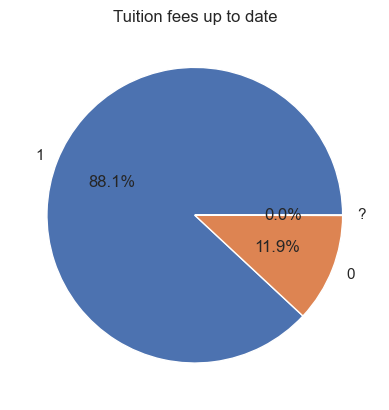

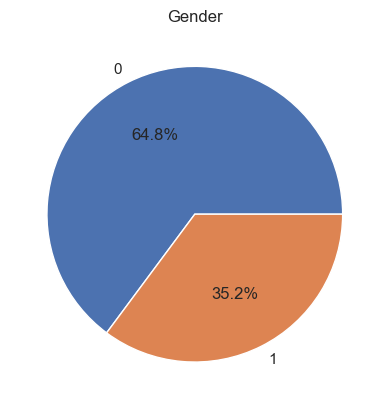

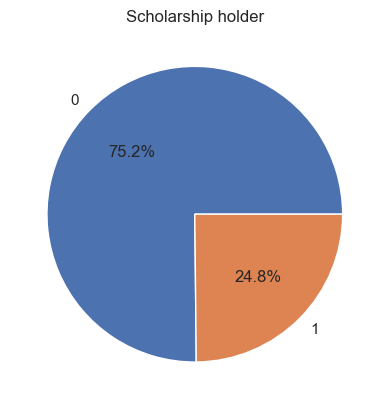

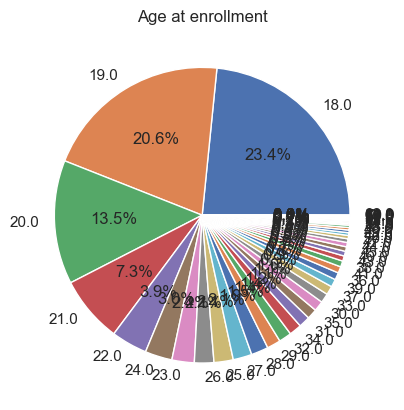

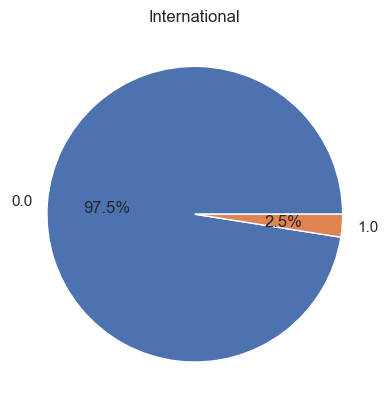

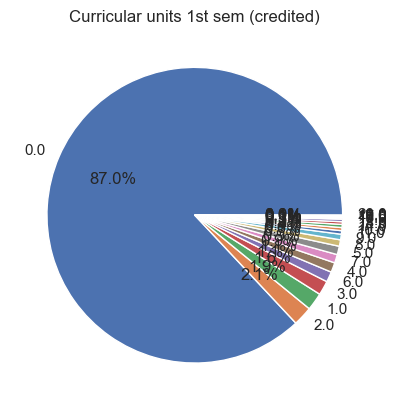

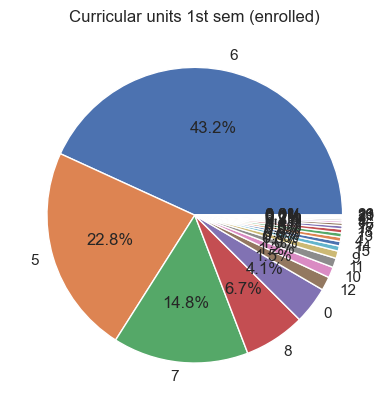

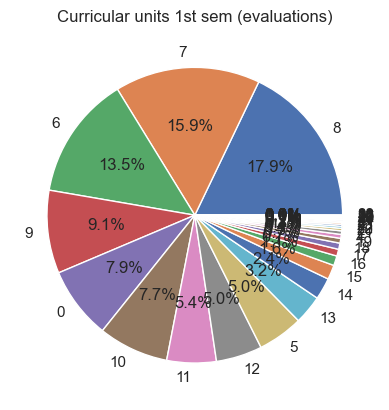

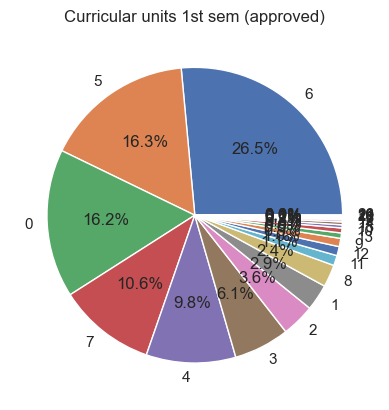

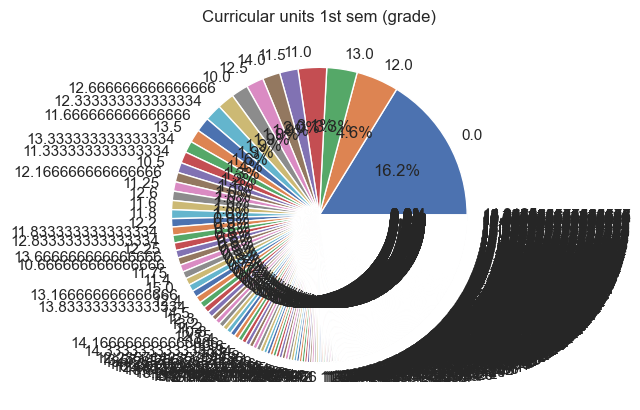

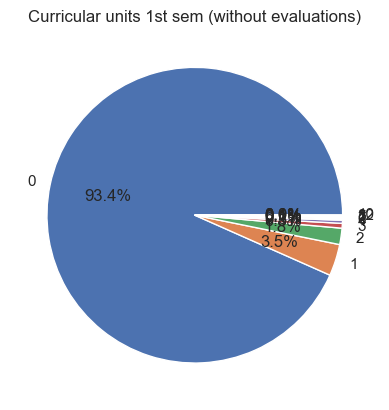

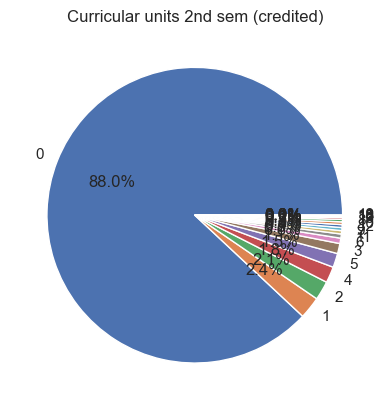

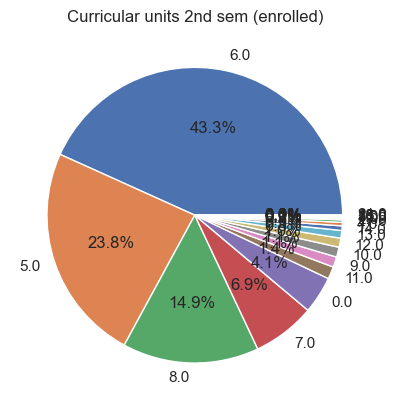

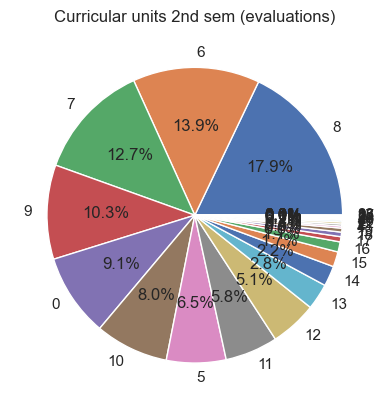

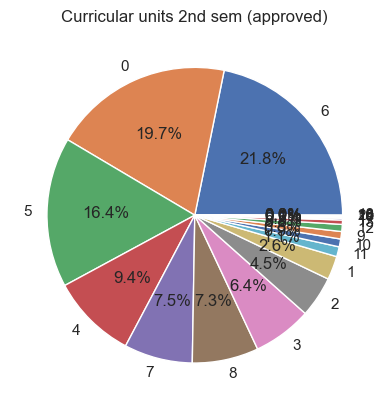

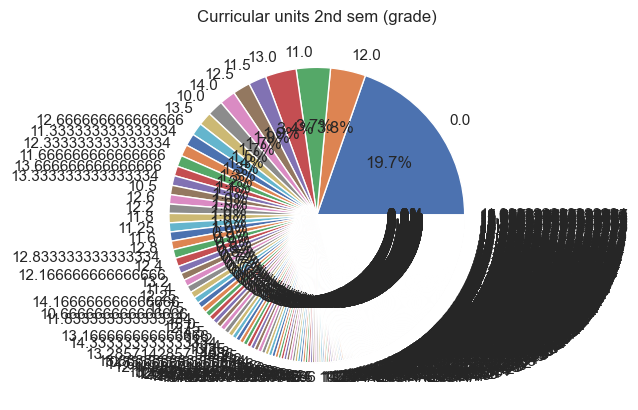

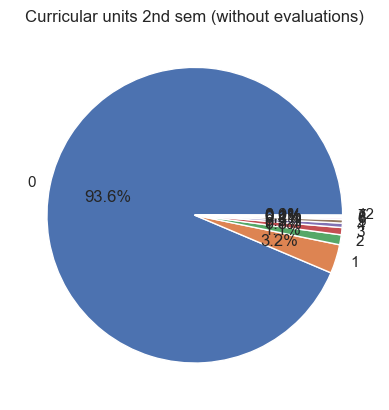

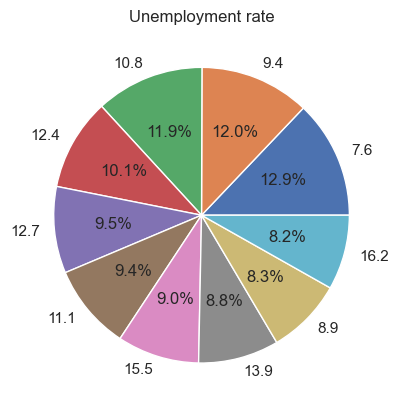

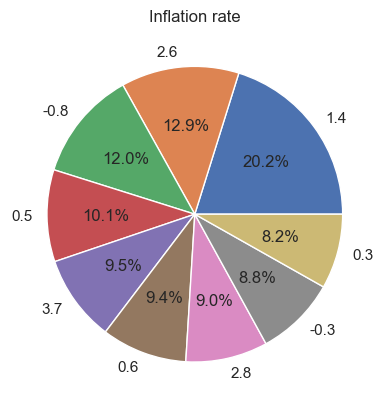

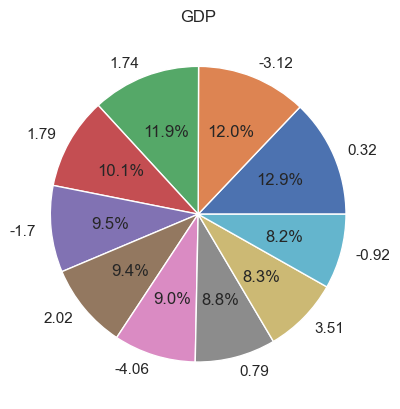

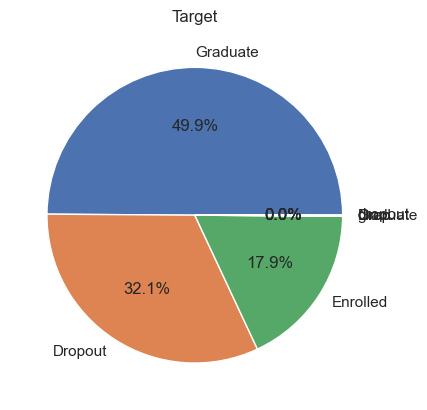

In [83]:
cols = ['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP', 'Target']
for c in cols:
    df[c].value_counts().plot.pie(autopct='%1.1f%%', title=c, ylabel='')
    plt.show()

In [84]:
scaler= preproc.StandardScaler()
df[features_to_standardize]=scaler.fit_transform(df[features_to_standardize])

In [85]:
df.describe() # we can see that the mean in the standariced features is close to 0

,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Mother's qualification,Father's qualification,Mother's occupation,Admission grade,Educational special needs,Debtor,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4423.000000,4.423000e+03,4421.000000,4424.000000,4424.000000,4.420000e+03,4424.000000,4423.000000,4423.000000,4.422000e+03,4424.000000,4423.000000,4424.000000,4424.000000,4.422000e+03,4423.000000,4.423000e+03,4.424000e+03,4.424000e+03,4.424000e+03,4.423000e+03,4.424000e+03,4.424000e+03,4.423000e+03,4.424000e+03,4.424000e+03,4.423000e+03,4.424000e+03,4.424000e+03,4.424000e+03,4.424000e+03
mean,18.663351,-9.960129e-17,8856.331147,0.890823,4.577758,-1.602740e-15,19.561935,22.271987,10.961338,-1.085417e-15,0.011528,0.113724,0.351718,0.248418,6.427343e-18,0.024870,-1.285178e-17,3.533440e-17,9.636656e-17,3.051608e-17,1.494019e-16,9.636656e-18,-3.212219e-18,1.052239e-16,-8.994212e-17,-1.509743e-16,1.381566e-16,3.212219e-18,-5.460771e-17,1.445498e-16,2.569775e-17
std,17.482509,1.000113e+00,2064.221611,0.311897,10.216592,1.000113e+00,15.603186,15.343244,26.421223,1.000113e+00,0.106760,0.317511,0.477560,0.432144,1.000113e+00,0.155746,1.000113e+00,1.000113e+00,1.000113e+00,1.000113e+00,1.000113e+00,1.000113e+00,1.000113e+00,1.000113e+00,1.000113e+00,1.000113e+00,1.000113e+00,1.000113e+00,1.000113e+00,1.000113e+00,1.000113e+00
min,1.000000,-1.315081e+00,33.000000,0.000000,1.000000,-2.852773e+00,1.000000,1.000000,0.000000,-2.209893e+00,0.000000,0.000000,0.000000,0.000000,-8.258692e-01,0.000000,-3.004430e-01,-2.528560e+00,-1.986068e+00,-1.521257e+00,-2.196813e+00,-1.992730e-01,-2.824423e-01,-2.838042e+00,-2.042630e+00,-1.471527e+00,-1.963227e+00,-1.994410e-01,-1.489043e+00,-1.466871e+00,-1.789667e+00
25%,1.000000,-5.538449e-01,9085.000000,1.000000,1.000000,-5.779288e-01,2.000000,3.000000,4.000000,-6.278705e-01,0.000000,0.000000,0.000000,0.000000,-5.623016e-01,0.000000,-3.004430e-01,-5.123476e-01,-5.501920e-01,-5.516038e-01,7.430696e-02,-1.992730e-01,-2.824423e-01,-5.609568e-01,-5.226824e-01,-8.080500e-01,9.980443e-02,-1.994410e-01,-8.132529e-01,-6.712423e-01,-7.498721e-01
50%,17.000000,-5.538449e-01,9238.000000,1.000000,1.000000,3.627913e-02,19.000000,19.000000,5.000000,-6.138193e-02,0.000000,0.000000,0.000000,0.000000,-4.305177e-01,0.000000,-3.004430e-01,-1.091051e-01,-7.156661e-02,9.483201e-02,3.397625e-01,-1.992730e-01,-2.824423e-01,-1.055398e-01,-1.603320e-02,1.871653e-01,3.780738e-01,-1.994410e-01,-1.750068e-01,1.243865e-01,1.401217e-01
75%,39.000000,2.073907e-01,9556.000000,1.000000,1.000000,5.594933e-01,37.000000,37.000000,9.000000,5.396486e-01,0.000000,0.000000,1.000000,0.000000,2.284015e-01,0.000000,-3.004430e-01,2.941373e-01,4.070588e-01,4.180499e-01,5.696176e-01,-1.992730e-01,-2.824423e-01,3.498772e-01,4.906160e-01,5.189037e-01,5.955717e-01,-1.994410e-01,8.762221e-01,9.923451e-01,7.877904e-01
max,57.000000,5.536040e+00,9991.000000,1.000000,43.000000,4.350900e+00,44.000000,44.000000,194.000000,4.353084e+00,1.000000,1.000000,1.000000,1.000000,6.158674e+00,1.000000,8.177130e+00,7.955743e+00,8.783003e+00,6.882407e+00,1.700222e+00,1.717184e+01,9.622009e+00,7.636549e+00,6.317081e+00,5.163242e+00,1.600814e+00,1.572225e+01,1.739731e+00,1.787974e+00,1.545607e+00


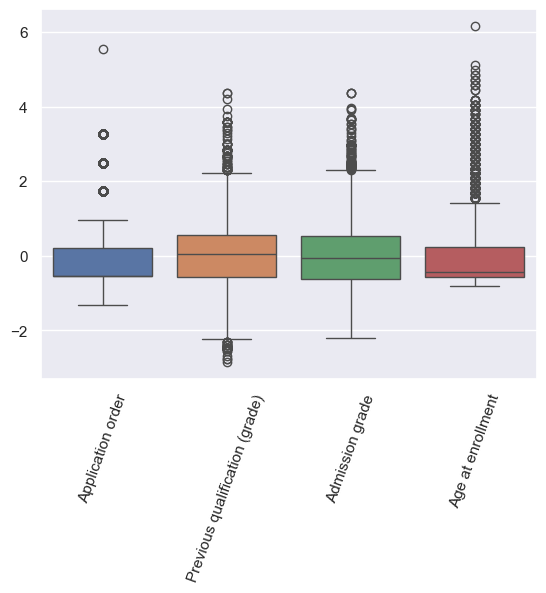

In [86]:
sns.boxplot(data=df[Enroll_Numerical_Features])
plt.xticks(rotation=70)
plt.show()

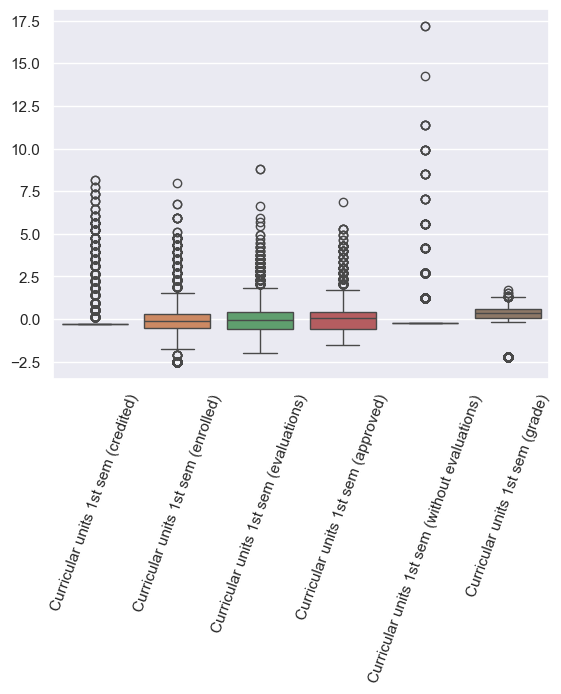

In [87]:
sns.boxplot(data=df[First_Semester_Numerical_Features])
plt.xticks(rotation=70)
plt.show()

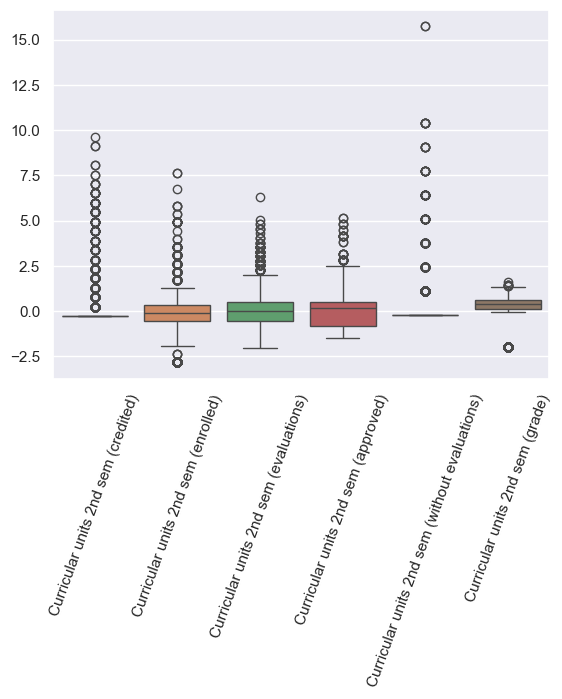

In [88]:
sns.boxplot(data=df[Second_Semester_Numerical_Features])
plt.xticks(rotation=70)
plt.show()

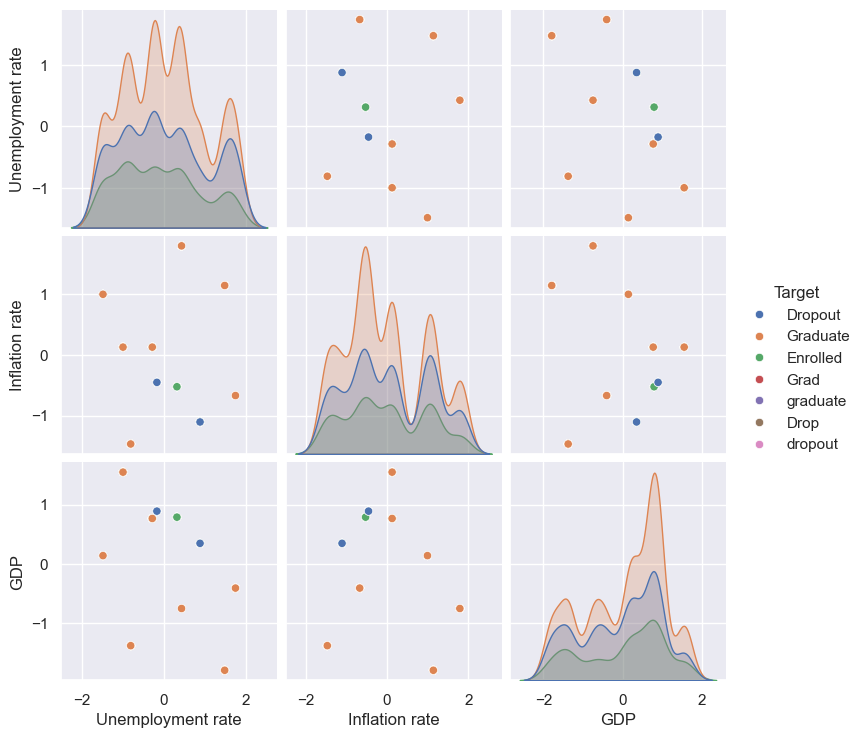

In [89]:
Economics_indicators=["Unemployment rate", "Inflation rate", "GDP"]
sns.pairplot(df,vars=Economics_indicators,hue="Target")
plt.show()

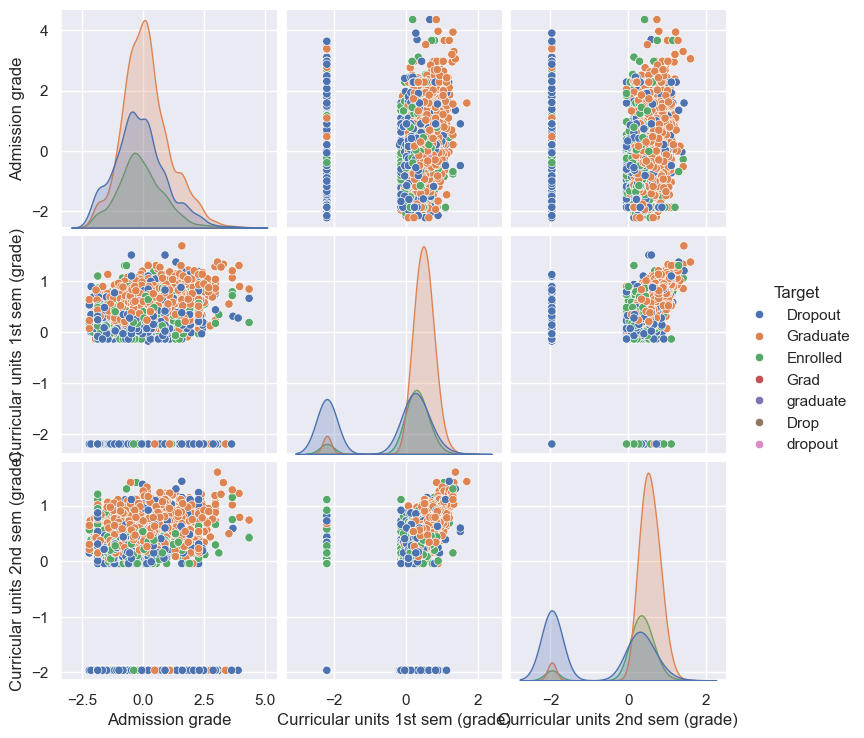

In [90]:
Grades=["Admission grade","Curricular units 1st sem (grade)","Curricular units 2nd sem (grade)"]
sns.pairplot(df,vars=Grades,hue="Target")
plt.show()  # por que miercale ya no muestra si antes mostrabaaaaaa

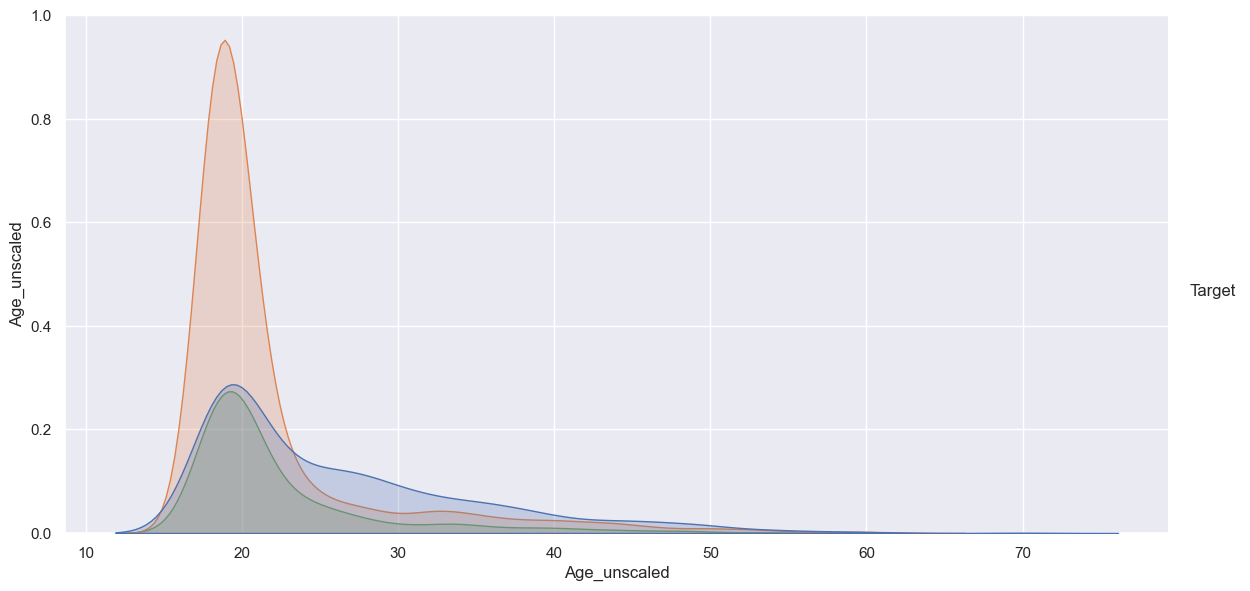

In [91]:
col_index = list(scaler.feature_names_in_).index('Age at enrollment')
df['Age_unscaled'] = (df['Age at enrollment'] * scaler.scale_[col_index]) + scaler.mean_[col_index]
Age = ["Age_unscaled"]
sns.pairplot(df, vars=Age, hue="Target", height=6, aspect=2)
plt.show()

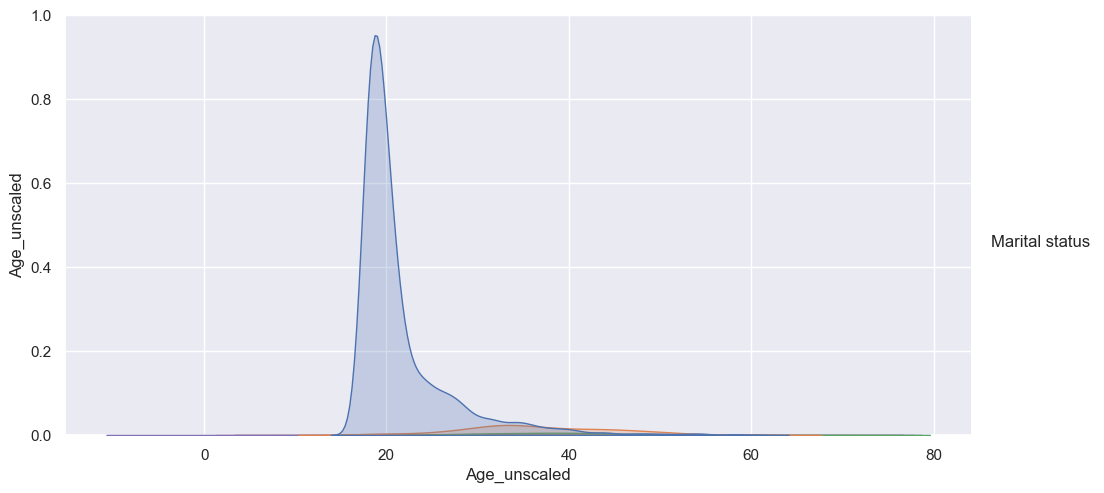

In [92]:
col_index = list(scaler.feature_names_in_).index('Age at enrollment')
df['Age_unscaled'] = (df['Age at enrollment'] * scaler.scale_[col_index]) + scaler.mean_[col_index]
Age = ["Age_unscaled"]
sns.pairplot(df, vars=Age, hue="Marital status", height=5, aspect=2)
plt.show()

In [93]:
correlation = df['Previous qualification (grade)'].corr(df['Curricular units 1st sem (grade)'])
print(correlation)

0.05992537769204066


In [94]:
correlation = df['Previous qualification (grade)'].corr(df['Curricular units 2nd sem (grade)'])
print(correlation)

0.053787291761972826


In [95]:
correlation = df['Curricular units 1st sem (grade)'].corr(df['Curricular units 2nd sem (grade)'])
print(correlation) #The grades bethuen semesters are related, but not whit the previous cualification grades

0.8371546968095418


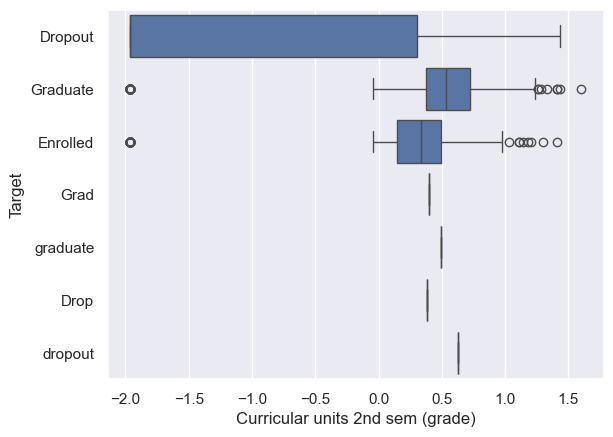

In [96]:
sns.boxplot(df, x="Curricular units 2nd sem (grade)", y="Target")
plt.show() 

In [97]:
df.rename(columns={"Curricular units 1st sem (credited)": "units 1st sem (credited)","Curricular units 1st sem (enrolled)": "units 1st sem (enrolled)","Curricular units 1st sem (evaluations)": "units 1st sem (evaluations)","Curricular units 1st sem (approved)": "units 1st sem (approved)","Curricular units 1st sem (grade)": "First sem grade","Curricular units 1st sem (without evaluations)": "units 1st sem (without evaluations)","Curricular units 2nd sem (credited)": "units 2nd sem (credited)","Curricular units 2nd sem (credited)": "units 2nd sem (credited)","Curricular units 2nd sem (enrolled)": "units 2nd sem (enrolled)","Curricular units 2nd sem (evaluations)": "units 2nd sem (evaluations)","Curricular units 2nd sem (approved)": "units 2nd sem (approved)","Curricular units 2nd sem (grade)": "Second sem grade","Curricular units 2nd sem (without evaluations)": "units 2nd sem (without evaluations)"}, inplace=True)

In [98]:
df

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,units 1st sem (credited),units 1st sem (enrolled),units 1st sem (evaluations),units 1st sem (approved),First sem grade,units 1st sem (without evaluations),units 2nd sem (credited),units 2nd sem (enrolled),units 2nd sem (evaluations),units 2nd sem (approved),Second sem grade,units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target,Age_unscaled
0,1,17.0,2.491097,171.0,1,1,-0.805413,1,19,12.0,5.0,9,0.021519,1,0,0.0,1,1,0,-0.430518,0.0,-0.300443,-2.528560,-1.986068,-1.521257,-2.196813,-0.199273,-0.282442,-2.838042,-2.042630,-1.471527,-1.963227,-0.199441,-0.287638,0.124386,0.765761,Dropout,20.0
1,1,15.0,-0.553845,9254.0,1,1,2.076056,1,1,3.0,3.0,3,1.071595,1,0,0.0,0,1,0,-0.562302,0.0,-0.300443,-0.109105,-0.550192,0.418050,0.693703,-0.199273,-0.282442,-0.105540,-0.522682,0.518904,0.659542,-0.199441,0.876222,-1.105222,0.347199,Graduate,19.0
2,1,1.0,2.491097,9070.0,1,1,-0.805413,1,37,37.0,9.0,9,-0.151191,1,0,0.0,0,1,0,-0.562302,0.0,-0.300443,-0.109105,-1.986068,-1.521257,-2.196813,-0.199273,-0.282442,-0.105540,-2.042630,-1.471527,-1.963227,-0.199441,-0.287638,0.124386,0.765761,Dropout,19.0
3,1,17.0,0.207391,9773.0,1,1,-0.805413,1,38,37.0,5.0,3,-0.510428,1,0,0.0,1,0,0,-0.430518,0.0,-0.300443,-0.109105,-0.071567,0.418050,0.575723,-0.199273,-0.282442,-0.105540,0.490616,0.187165,0.416456,-0.199441,-0.813253,-1.466871,-1.375511,Graduate,20.0
4,2,39.0,-0.553845,8014.0,0,1,-2.473632,1,37,38.0,9.0,9,1.002511,0,0,0.0,1,0,0,2.864078,0.0,-0.300443,-0.109105,0.167746,0.094832,0.349594,-0.199273,-0.282442,-0.105540,-0.522682,0.518904,0.531602,-0.199441,0.876222,-1.105222,0.347199,Graduate,45.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4419,1,1.0,3.252333,9773.0,1,1,-0.577929,1,1,1.0,5.0,4,-0.330809,0,0,0.0,1,1,0,-0.562302,0.0,-0.300443,-0.109105,-0.310879,0.094832,0.611117,-0.199273,-0.282442,-0.105540,-0.016033,0.187165,0.467632,-0.199441,1.476924,1.137005,-1.789667,Graduate,19.0
4420,1,1.0,0.207391,9773.0,1,1,-0.957069,105,1,1.0,9.0,9,-0.551878,1,0,1.0,0,0,0,-0.694085,1.0,-0.300443,-0.109105,-0.550192,0.418050,0.280772,-0.199273,-0.282442,-0.105540,-0.522682,-0.808050,0.147782,-0.199441,-0.175007,-0.454253,0.889126,Dropout,18.0
4421,1,1.0,-0.553845,9500.0,1,1,1.621087,1,37,37.0,9.0,9,1.555183,1,0,0.0,1,0,1,0.887321,0.0,-0.300443,0.294137,-0.071567,0.741268,0.882103,-0.199273,-0.282442,0.805294,0.237291,-1.139788,0.627557,-0.199441,0.876222,-1.105222,0.347199,Dropout,30.0
4422,1,1.0,-0.553845,9147.0,1,1,3.592619,1,37,37.0,7.0,4,1.852244,1,0,0.0,1,0,1,-0.430518,0.0,-0.300443,-0.512348,-0.789505,0.094832,0.652410,-0.199273,-0.282442,-0.560957,-0.522682,0.187165,0.339692,-0.199441,-0.813253,-1.466871,-1.375511,Graduate,20.0


In [99]:
label_encoder = LabelEncoder()
df['encoded_Target'] = label_encoder.fit_transform(df['Target'])
df

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,units 1st sem (credited),units 1st sem (enrolled),units 1st sem (evaluations),units 1st sem (approved),First sem grade,units 1st sem (without evaluations),units 2nd sem (credited),units 2nd sem (enrolled),units 2nd sem (evaluations),units 2nd sem (approved),Second sem grade,units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target,Age_unscaled,encoded_Target
0,1,17.0,2.491097,171.0,1,1,-0.805413,1,19,12.0,5.0,9,0.021519,1,0,0.0,1,1,0,-0.430518,0.0,-0.300443,-2.528560,-1.986068,-1.521257,-2.196813,-0.199273,-0.282442,-2.838042,-2.042630,-1.471527,-1.963227,-0.199441,-0.287638,0.124386,0.765761,Dropout,20.0,1
1,1,15.0,-0.553845,9254.0,1,1,2.076056,1,1,3.0,3.0,3,1.071595,1,0,0.0,0,1,0,-0.562302,0.0,-0.300443,-0.109105,-0.550192,0.418050,0.693703,-0.199273,-0.282442,-0.105540,-0.522682,0.518904,0.659542,-0.199441,0.876222,-1.105222,0.347199,Graduate,19.0,4
2,1,1.0,2.491097,9070.0,1,1,-0.805413,1,37,37.0,9.0,9,-0.151191,1,0,0.0,0,1,0,-0.562302,0.0,-0.300443,-0.109105,-1.986068,-1.521257,-2.196813,-0.199273,-0.282442,-0.105540,-2.042630,-1.471527,-1.963227,-0.199441,-0.287638,0.124386,0.765761,Dropout,19.0,1
3,1,17.0,0.207391,9773.0,1,1,-0.805413,1,38,37.0,5.0,3,-0.510428,1,0,0.0,1,0,0,-0.430518,0.0,-0.300443,-0.109105,-0.071567,0.418050,0.575723,-0.199273,-0.282442,-0.105540,0.490616,0.187165,0.416456,-0.199441,-0.813253,-1.466871,-1.375511,Graduate,20.0,4
4,2,39.0,-0.553845,8014.0,0,1,-2.473632,1,37,38.0,9.0,9,1.002511,0,0,0.0,1,0,0,2.864078,0.0,-0.300443,-0.109105,0.167746,0.094832,0.349594,-0.199273,-0.282442,-0.105540,-0.522682,0.518904,0.531602,-0.199441,0.876222,-1.105222,0.347199,Graduate,45.0,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4419,1,1.0,3.252333,9773.0,1,1,-0.577929,1,1,1.0,5.0,4,-0.330809,0,0,0.0,1,1,0,-0.562302,0.0,-0.300443,-0.109105,-0.310879,0.094832,0.611117,-0.199273,-0.282442,-0.105540,-0.016033,0.187165,0.467632,-0.199441,1.476924,1.137005,-1.789667,Graduate,19.0,4
4420,1,1.0,0.207391,9773.0,1,1,-0.957069,105,1,1.0,9.0,9,-0.551878,1,0,1.0,0,0,0,-0.694085,1.0,-0.300443,-0.109105,-0.550192,0.418050,0.280772,-0.199273,-0.282442,-0.105540,-0.522682,-0.808050,0.147782,-0.199441,-0.175007,-0.454253,0.889126,Dropout,18.0,1
4421,1,1.0,-0.553845,9500.0,1,1,1.621087,1,37,37.0,9.0,9,1.555183,1,0,0.0,1,0,1,0.887321,0.0,-0.300443,0.294137,-0.071567,0.741268,0.882103,-0.199273,-0.282442,0.805294,0.237291,-1.139788,0.627557,-0.199441,0.876222,-1.105222,0.347199,Dropout,30.0,1
4422,1,1.0,-0.553845,9147.0,1,1,3.592619,1,37,37.0,7.0,4,1.852244,1,0,0.0,1,0,1,-0.430518,0.0,-0.300443,-0.512348,-0.789505,0.094832,0.652410,-0.199273,-0.282442,-0.560957,-0.522682,0.187165,0.339692,-0.199441,-0.813253,-1.466871,-1.375511,Graduate,20.0,4


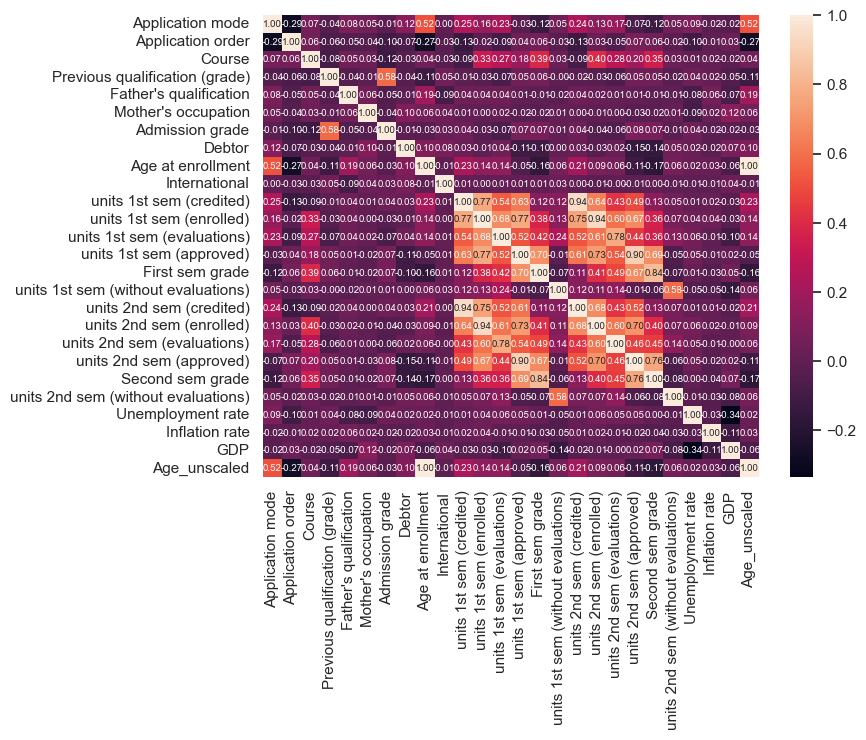

In [100]:
Float_Features=df.select_dtypes(include='float64')
Correlation_matrix=Float_Features.corr()
plt.figure(figsize=(8, 6))
sns.heatmap(Correlation_matrix, annot=True, fmt='.2f',annot_kws={"size": 7},)
plt.show()

In [105]:
X = df
y = df['Target']
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state = 1)
X.shape, y.shape, X_train.shape, X_test.shape, y_train.shape, y_test.shape

((4424, 39), (4424,), (3318, 39), (1106, 39), (3318,), (1106,))

In [107]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled  = scaler.transform(X_test)
X_scaled = scaler.transform(X)
print(X_train_scaled, '\t', X_test_scaled, '\t', X_scaled)

ValueError: could not convert string to float: '?'

In [ ]:
from sklearn.decomposition import PCA
pca = PCA(n_components = 2)
X_pca = pca.fit_transform(X_scaled)
print("Original shape: {}".format(str(X_scaled.shape)))
print("Reduced shape: {}".format(str(X_pca.shape)))

In [ ]:
print(pca.explained_variance_)